# Pobreza e desigualdades no Brasil
## Parte 1 - análise exploratória e indicadores
**Recorte histórico: 2012–2022; foco: 2022.** Fonte: IBGE, Estatísticas de Gênero, 3ª edição (2024), Tabela 1.16, PNAD Contínua.

**Pergunta principal:** como a incidência de pobreza varia por sexo, cor ou raça, idade, condição de ocupação e situação do domicílio?
**Motivação:** apoiar a leitura de desigualdades por estudantes, sociedade civil e gestores. O produto reúne dados tratados, indicadores, gráficos e uma segmentação exploratória. A relevância para São Paulo é temática; esta fonte não contém recorte estadual ou municipal e não autoriza extrapolações locais.

O enunciado original da parte 1 não foi fornecido. Esta versão desenvolve as perguntas do notebook enviado e os tópicos de dados, visualização e limitações dos requisitos da apresentação. Não caracteriza 2022 como situação atual de 2026.


In [1]:
from pathlib import Path
import json, hashlib, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
warnings.filterwarnings('ignore', message='.*xlrd engine.*')
ROOT = Path.cwd()
if not (ROOT / 'dados').exists():
    raise RuntimeError('Abra o notebook na pasta do projeto, que contém dados/.')
OUT = ROOT / 'resultados'
OUT.mkdir(exist_ok=True)
plt.rcParams.update({'figure.figsize': (10, 5), 'axes.spines.top': False, 'axes.spines.right': False})
FONTE = ROOT / 'dados/originais/Tabela 1.16.xls'
print('SHA256 da fonte:', hashlib.sha256(FONTE.read_bytes()).hexdigest())


Matplotlib is building the font cache; this may take a moment.


SHA256 da fonte: df51ea5c8ba4ed6da4474760cec6ee3b1a1302966dec0c5cdfaee579d264bb8c


## Dados e pré-processamento
Uma linha é uma **estimativa publicada para segmento × sexo × ano**, não uma pessoa. `extrema` e `pobreza` são percentuais de pessoas com rendimento domiciliar per capita abaixo, respectivamente, de US$ 2,15 e US$ 6,85 por dia em PPC 2017. São as linhas históricas desta publicação; não se converte usando o câmbio comercial. A linha de pobreza inclui a extrema pobreza.

`cv_extrema` e `cv_pobreza` são coeficientes de variação em %. `ano` é a referência; `grupo` identifica a dimensão; `segmento` é a categoria; `sexo` segue a classificação publicada pelo IBGE. Taxas já possuem denominadores próprios: não somar nem tirar média simples para obter a taxa nacional.

A leitura percorre abas e cabeçalhos, preserva as seis colunas numéricas e associa CV pelo nome da categoria. Valida chaves únicas, limites 0–100 e extrema ≤ pobreza. Não imputa ausências. O notebook original procurava “Menos de” na primeira coluna, embora as linhas de pobreza estejam nos cabeçalhos das colunas numéricas, e buscava homens/mulheres em linhas de categorias: por isso o gap retornava NaN.

**Cobertura e viés:** exclui pensionistas, empregados domésticos e parentes de empregados domésticos na condição no domicílio. Não publica amarelos, indígenas ou cor/raça sem declaração. Os recortes se sobrepõem: uma mulher pode aparecer também nos recortes de idade, raça e domicílio. O número de linhas não é o tamanho da amostra de entrevistados. A tabela não informa esse tamanho. Há erro amostral, sem covariâncias suficientes para testes de diferenças entre todos os recortes.


In [2]:
xls = pd.ExcelFile(FONTE)
registros = []
for ano in [s for s in xls.sheet_names if s.isdigit()]:
    raw = pd.read_excel(xls, sheet_name=ano, header=None)
    cv = pd.read_excel(xls, sheet_name=f'{ano} (CV)', header=None)
    grupo = 'Geral'
    for i, row in raw.iterrows():
        if pd.isna(row.iloc[0]): continue
        nome = str(row.iloc[0]).strip()
        if nome.startswith(('Cor ou raça', 'Grupos de idade', 'Condição de ocupação', 'Situação no domicílio')):
            grupo = nome.replace(' (2)', '')
            continue
        vals = pd.to_numeric(row.iloc[1:7], errors='coerce')
        if vals.isna().any(): continue
        cvrow = cv.loc[cv[0].astype(str).str.strip().eq(nome)]
        assert len(cvrow) == 1, (ano, nome)
        for sexo, e, p in [('Total',1,4), ('Homem',2,5), ('Mulher',3,6)]:
            registros.append(dict(ano=int(ano), grupo='Geral' if nome=='Total' else grupo,
                segmento=nome, sexo=sexo, extrema=float(row.iloc[e]), pobreza=float(row.iloc[p]),
                cv_extrema=float(cvrow.iloc[0,e]), cv_pobreza=float(cvrow.iloc[0,p])))
dados = pd.DataFrame(registros)
assert not dados.duplicated(['ano','grupo','segmento','sexo']).any()
assert dados[['extrema','pobreza']].notna().all().all()
assert dados.extrema.between(0,100).all() and dados.pobreza.between(0,100).all()
assert (dados.extrema <= dados.pobreza).all()
dados.to_csv(OUT/'dados_tratados.csv',index=False,encoding='utf-8-sig')
print(f'{len(dados)} registros agregados; {dados.ano.nunique()} anos; {dados.segmento.nunique()} segmentos incluindo Total.')
print('Ausências nas taxas:', dados[['extrema','pobreza']].isna().sum().to_dict())
display(dados.head(9))


363 registros agregados; 11 anos; 11 segmentos incluindo Total.
Ausências nas taxas: {'extrema': 0, 'pobreza': 0}


,ano,grupo,segmento,sexo,extrema,pobreza,cv_extrema,cv_pobreza
0,2022,Geral,Total,Total,5.865603,31.621359,1.859696,0.648219
1,2022,Geral,Total,Homem,5.664764,30.911550,1.930335,0.673144
2,2022,Geral,Total,Mulher,6.057625,32.300004,2.091716,0.719940
3,2022,Cor ou raça,Brancos,Total,3.515632,20.968241,2.794686,1.336142
4,2022,Cor ou raça,Brancos,Homem,3.413257,20.620952,3.346521,1.443422
5,2022,Cor ou raça,Brancos,Mulher,3.609464,21.286551,3.168020,1.477536
6,2022,Cor ou raça,Pretos ou pardos,Total,7.703389,39.953215,2.059405,0.605429
7,2022,Cor ou raça,Pretos ou pardos,Homem,7.363165,38.623567,2.063282,0.673442
8,2022,Cor ou raça,Pretos ou pardos,Mulher,8.040340,41.270073,2.415877,0.668192


## KPIs | Brasil, 2022

In [3]:
atual = dados.query('ano == 2022').copy()
geral = atual.query("segmento == 'Total'").set_index('sexo')
totais = atual.query("sexo == 'Total'").set_index('segmento')
kpis = {
 'Extrema pobreza nacional (%)': geral.loc['Total','extrema'],
 'Pobreza nacional (%)': geral.loc['Total','pobreza'],
 'Gap mulheres - homens (p.p.)': geral.loc['Mulher','pobreza']-geral.loc['Homem','pobreza'],
 'Gap pretos/pardos - brancos (p.p.)': totais.loc['Pretos ou pardos','pobreza']-totais.loc['Brancos','pobreza'],
 'Pobreza de 0 a 14 anos (%)': totais.loc['0 a 14 anos','pobreza'],
 'Gap rural - urbana (p.p.)': totais.loc['Rural','pobreza']-totais.loc['Urbana','pobreza']}
display(pd.Series(kpis,name='Valor').round(2).to_frame())
(OUT/'indicadores.json').write_text(json.dumps(kpis,ensure_ascii=False,indent=2),encoding='utf-8')


,Valor
Extrema pobreza nacional (%),5.87
Pobreza nacional (%),31.62
Gap mulheres - homens (p.p.),1.39
Gap pretos/pardos - brancos (p.p.),18.98
Pobreza de 0 a 14 anos (%),49.06
Gap rural - urbana (p.p.),25.32


317

## Visualizações

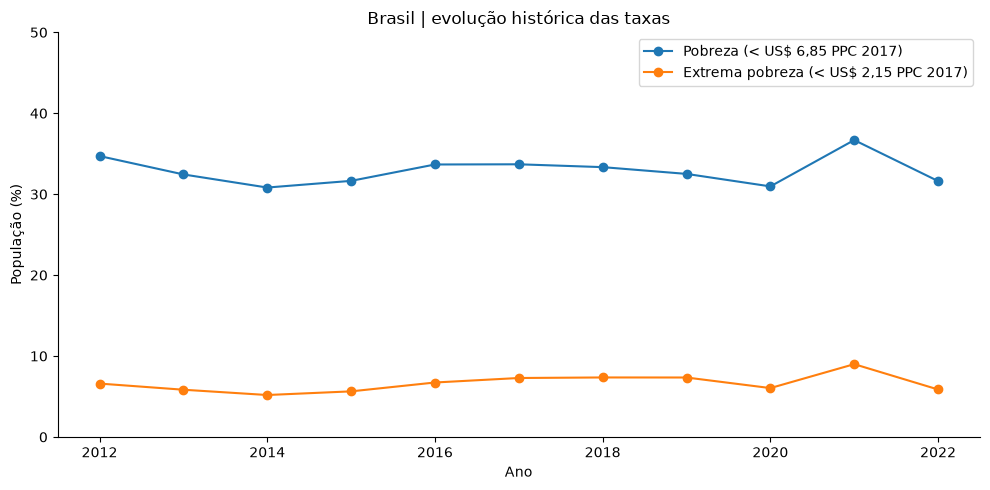

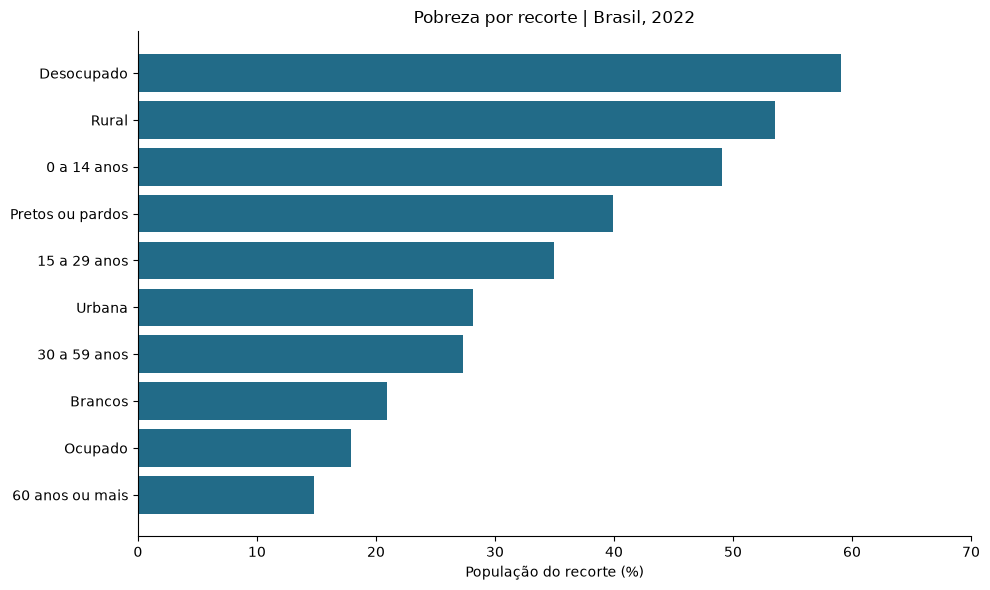

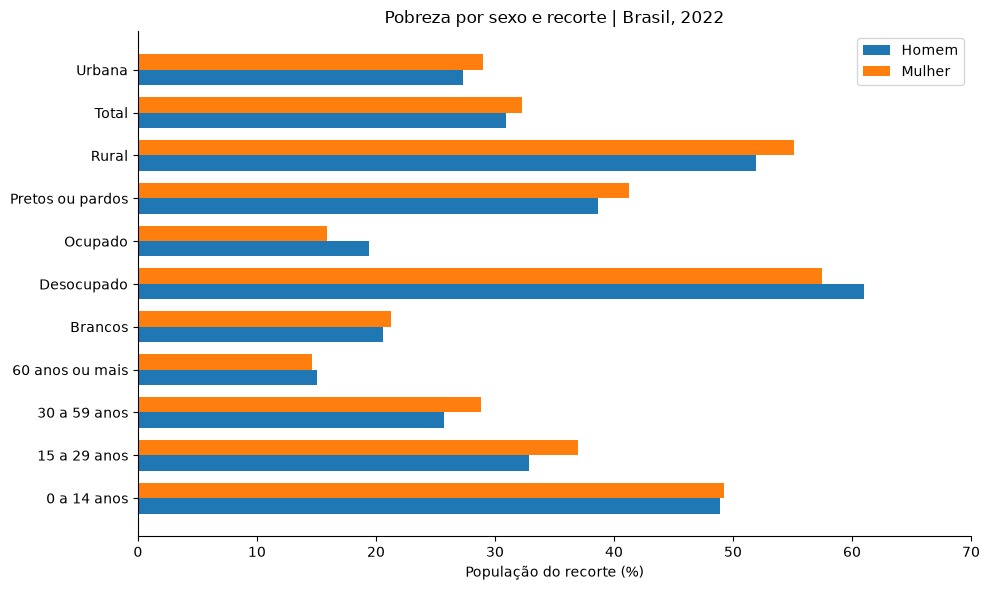

In [4]:
fig, ax = plt.subplots()
serie = dados.query("segmento == 'Total' and sexo == 'Total'").sort_values('ano')
ax.plot(serie.ano,serie.pobreza,'o-',label='Pobreza (< US$ 6,85 PPC 2017)')
ax.plot(serie.ano,serie.extrema,'o-',label='Extrema pobreza (< US$ 2,15 PPC 2017)')
ax.set(title='Brasil | evolução histórica das taxas',ylabel='População (%)',xlabel='Ano',ylim=(0,50))
ax.legend(); fig.tight_layout(); fig.savefig(OUT/'serie.png',dpi=140); plt.show()
fig,ax=plt.subplots(figsize=(10,6))
comparacao=atual.query("sexo == 'Total' and segmento != 'Total'").sort_values('pobreza')
ax.barh(comparacao.segmento,comparacao.pobreza,color='#226b88')
ax.set(title='Pobreza por recorte | Brasil, 2022',xlabel='População do recorte (%)',xlim=(0,70))
fig.tight_layout(); fig.savefig(OUT/'recortes.png',dpi=140); plt.show()
fig,ax=plt.subplots(figsize=(10,6))
sexo=atual.query("sexo != 'Total'").pivot(index='segmento',columns='sexo',values='pobreza')
y=np.arange(len(sexo))
ax.barh(y-.18,sexo.Homem,.36,label='Homem'); ax.barh(y+.18,sexo.Mulher,.36,label='Mulher')
ax.set(yticks=y,yticklabels=sexo.index,xlabel='População do recorte (%)',title='Pobreza por sexo e recorte | Brasil, 2022',xlim=(0,70))
ax.legend(); fig.tight_layout(); fig.savefig(OUT/'sexo.png',dpi=140); plt.show()


## Indicadores e leitura dos resultados
Os dois primeiros KPIs reproduzem as taxas oficiais; os gaps são indicadores derivados: **taxa A − taxa B**, em pontos percentuais, sem somar populações. O denominador da taxa de infância é a população de 0 a 14 anos, e não a população brasileira inteira.

As maiores taxas se concentram em desocupados, residentes rurais e crianças; pretos ou pardos apresentam taxa superior à de brancos. A diferença nacional entre mulheres e homens existe, mas não tem o mesmo sentido em todos os recortes: entre ocupados, desocupados e pessoas de 60 anos ou mais a taxa feminina é menor. Assim, a afirmação original de superioridade feminina generalizada precisava ser corrigida. São associações descritivas, não evidências de causalidade.

## Proposta de data app e tomada de decisão
Um painel Streamlit é adequado para comparar indicadores: `st.metric` para as duas taxas e gap por sexo; filtro de ano e de dimensão demográfica; linhas para evolução, barras para recortes e dispersão para clusters. Cada filtro deve indicar sua base e manter homens/mulheres disponíveis para calcular o gap. Não recalcular o total nacional pela média das categorias. Exportações em `resultados/` permitem integrar as partes 1 e 3 à parte 2.

O painel pode orientar perguntas e demanda por diagnóstico local, mas não prever efeitos de transferência de renda: isso exigiria microdados, regra da política e identificação causal. Esta entrega não implementa a parte 2. Gráficos dos notebooks são estáticos, e interatividade está proposta para a interface.
